# NHTSA Recall Lag Analysis: Statistics and Charts

This notebook reads the tables and views built by `sql/01`–`10` and adds what SQL can't do well
(confidence intervals and significance tests). Every chart is saved to `Results/charts/`, every table to
`Results/tables/`, and the key numbers to `Results/key_numbers.json`, which `Results/results.md` quotes.

**Steps**

1. Measure the size of the complaint → recall join.
2. Compute the lag from first complaint to recall, per campaign, and test how sensitive it is to the lookback window.
3. Compare lag across manufacturers and components, with 95% confidence intervals.
4. Look at severity (deaths, injuries, crashes, fires) by component.
5. Test whether severe complaints are followed by a recall more often or faster.
6. Look at trends over time.
7. Measure how often a complaint is followed by a recall.
8. Test whether complaint spikes predict recalls.
9. Classify air bag recalls by failure mode.
10. Compare manufacturer-initiated and NHTSA-influenced recalls.

Run order: `01_data_cleaning.ipynb` → `sql/run_all.ps1` → this notebook.

In [1]:
from pathlib import Path
import json
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import sqlalchemy as sa
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.width", 160)

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "datasets").is_dir() or (p / "sql").is_dir():
            return p
    raise FileNotFoundError(start)

ROOT = find_project_root(Path.cwd().resolve())
RES = ROOT / "Results"
CHARTS, TABLES = RES / "charts", RES / "tables"
CHARTS.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

odbc = "DRIVER={ODBC Driver 17 for SQL Server};SERVER=localhost;DATABASE=NHTSA_v2;Trusted_Connection=yes;"
engine = sa.create_engine("mssql+pyodbc:///?odbc_connect=" + quote_plus(odbc))

def q(sql: str) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(sa.text(sql), conn)

def save(df: pd.DataFrame, name: str) -> pd.DataFrame:
    df.to_csv(TABLES / f"{name}.csv", index=False)
    return df

KEY = {}   # headline numbers, written to key_numbers.json at the end
rng = np.random.default_rng(42)

def median_ci(x, n_boot=2000, alpha=0.05):
    """Median with a percentile-bootstrap 95% confidence interval."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    boots = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
    return np.median(x), np.quantile(boots, alpha / 2), np.quantile(boots, 1 - alpha / 2)

### Chart style

One accessible palette (validated for colour-vision deficiency), thin marks, light grid, direct labels.
Single-series charts use one blue; a highlighted bar uses orange.

In [2]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

matplotlib.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def finish(fig, ax, name, subtitle=None):
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK2, fontsize=9, va="bottom")
    fig.savefig(CHARTS / f"{name}.png")
    plt.show()
    plt.close(fig)

def hbar(labels, values, title, xlabel, name, subtitle=None, fmt="{:,.0f}", highlight=None, xerr=None):
    """Sorted horizontal bar chart with direct value labels."""
    fig, ax = plt.subplots(figsize=(8, 0.38 * len(labels) + 1.4))
    colors = [ORANGE if (highlight is not None and l in highlight) else BLUE for l in labels]
    y = np.arange(len(labels))
    ax.barh(y, values, color=colors, height=0.62, xerr=xerr,
            error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2})
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=22 if subtitle else 8)
    right = (np.asarray(values) + (np.asarray(xerr)[1] if xerr is not None else 0))
    for yi, v, r in zip(y, values, right):
        ax.text(r + max(right) * 0.01, yi, fmt.format(v), va="center", color=INK2, fontsize=8.5)
    ax.set_xlim(0, max(right) * 1.15)
    finish(fig, ax, name, subtitle)

## 1. How big is the complaint → recall join?

A complaint is matched to a recall only when the recall covers the same manufacturer, component, model and
model year. This cell counts the matched pairs, the distinct complaints that matched, and the average number
of recalls each matched complaint pairs with.

In [3]:
sizes = q("SELECT COUNT_BIG(*) AS pairs, COUNT(DISTINCT ODINO) AS complaints FROM v2.complaint_recall_pairs")
sizes.insert(0, "join_type", "OEM + component + model + model year")
sizes["pairs_per_complaint"] = (sizes["pairs"] / sizes["complaints"]).round(2)
sizes = save(sizes, "01_join_size")
KEY["pairs"] = int(sizes.pairs[0])
KEY["matched_complaints"] = int(sizes.complaints[0])
KEY["pairs_per_complaint"] = float(sizes.pairs_per_complaint[0])
sizes

,join_type,pairs,complaints,pairs_per_complaint
0,OEM + component + model + model year,397145,239908,1.66


## 2. Campaign-level lag

One observation per recall campaign: days from the first matching owner complaint to the recall.
Only campaigns from 2005 on with at least one matching complaint (see `v2.params`).

{
 "campaigns_with_prior_complaint": 3246,
 "pct_campaigns_with_prior_complaint": 50.6,
 "median_lag_first_days": 766,
 "median_lag_first_ci": [
  711,
  831
 ],
 "median_lag_signal_days": 898,
 "median_lag_signal_ci": [
  835,
  950
 ],
 "signal_campaigns": 2368,
 "p25_lag_first_days": 260,
 "p75_lag_first_days": 1889,
 "p90_lag_first_days": 3249,
 "median_prior_complaints": 10.0,
 "pct_lag_over_5y": 26.0
}


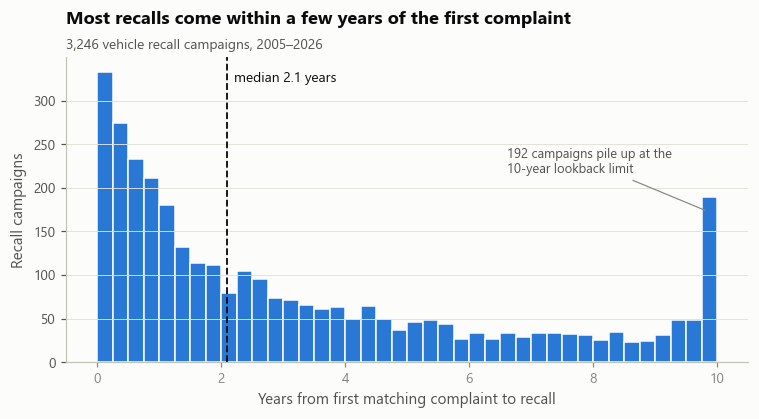

In [4]:
camp = q("SELECT * FROM v2.vw_lag_campaigns")
camp["lag_first_years"] = camp["LAG_FIRST_DAYS"] / 365.25
all_window = q("SELECT COUNT(*) AS n, SUM(CASE WHEN PRIOR_COMPLAINTS > 0 THEN 1 ELSE 0 END) AS with_complaint FROM v2.campaign_lag WHERE IN_LAG_WINDOW = 1")

m, lo, hi = median_ci(camp["LAG_FIRST_DAYS"])
ms, los, his = median_ci(camp["LAG_SIGNAL_DAYS"])
KEY.update({
    "campaigns_in_window": int(all_window.n[0]),
    "campaigns_with_prior_complaint": int(all_window.with_complaint[0]),
    "pct_campaigns_with_prior_complaint": round(100 * all_window.with_complaint[0] / all_window.n[0], 1),
    "median_lag_first_days": round(m), "median_lag_first_ci": [round(lo), round(hi)],
    "median_lag_signal_days": round(ms), "median_lag_signal_ci": [round(los), round(his)],
    "signal_campaigns": int(camp["LAG_SIGNAL_DAYS"].notna().sum()),
    "p25_lag_first_days": round(camp["LAG_FIRST_DAYS"].quantile(.25)),
    "p75_lag_first_days": round(camp["LAG_FIRST_DAYS"].quantile(.75)),
    "p90_lag_first_days": round(camp["LAG_FIRST_DAYS"].quantile(.90)),
    "median_prior_complaints": float(camp["PRIOR_COMPLAINTS"].median()),
    "pct_lag_over_5y": round(100 * (camp["LAG_FIRST_DAYS"] > 1826).mean(), 1),
})
print(json.dumps({k: KEY[k] for k in list(KEY)[-12:]}, indent=1))

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 10.25, 0.25)
ax.hist(camp["lag_first_years"], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(m / 365.25, color=INK, linewidth=1.2, linestyle="--")
ax.text(m / 365.25 + 0.1, ax.get_ylim()[1] * 0.92, f"median {m / 365.25:.1f} years", color=INK, fontsize=9)
at_cap = int((camp["lag_first_years"] > 9.75).sum())
KEY["campaigns_at_lookback_cap"] = at_cap
ax.annotate(f"{at_cap} campaigns pile up at the\n10-year lookback limit", xy=(9.85, at_cap * 0.9), xytext=(6.6, ax.get_ylim()[1] * 0.62),
            color=INK2, fontsize=8.5, arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8})
ax.set_xlabel("Years from first matching complaint to recall")
ax.set_ylabel("Recall campaigns")
ax.grid(axis="x", visible=False)
ax.set_title("Most recalls come within a few years of the first complaint", pad=22)
finish(fig, ax, "02_lag_distribution", f"{len(camp):,} vehicle recall campaigns, 2005–{pd.Timestamp(q('SELECT EXTRACT_DATE FROM v2.params').iloc[0,0]).year}")

### Sensitivity: does the lookback window drive the answer?

The lag is measured with a lookback of up to 10 years before the recall. This check recomputes the median
lag on the same campaigns with shorter caps to show how much the window choice moves the result.

In [5]:
pairs_lag = q("""
SELECT p.CAMPNO, p.DAYS_BEFORE_RECALL
FROM v2.complaint_recall_pairs AS p
JOIN v2.vw_lag_campaigns AS c ON c.CAMPNO = p.CAMPNO
""")
rows = []
for cap_years in [1, 2, 5, 10]:
    first = pairs_lag[pairs_lag.DAYS_BEFORE_RECALL <= cap_years * 365.25].groupby("CAMPNO").DAYS_BEFORE_RECALL.max()
    rows.append({"lookback_cap_years": cap_years, "campaigns": len(first), "median_lag_first_days": first.median()})
sens = save(pd.DataFrame(rows), "02b_lookback_sensitivity")
KEY["lookback_sensitivity"] = sens.to_dict("records")
sens

,lookback_cap_years,campaigns,median_lag_first_days
0,1,2955,302.0
1,2,3131,526.0
2,5,3232,730.0
3,10,3246,766.0


## 3. Lag by manufacturer, with 95% confidence intervals

Kruskal-Wallis across OEMs: H=19.3, p=0.023


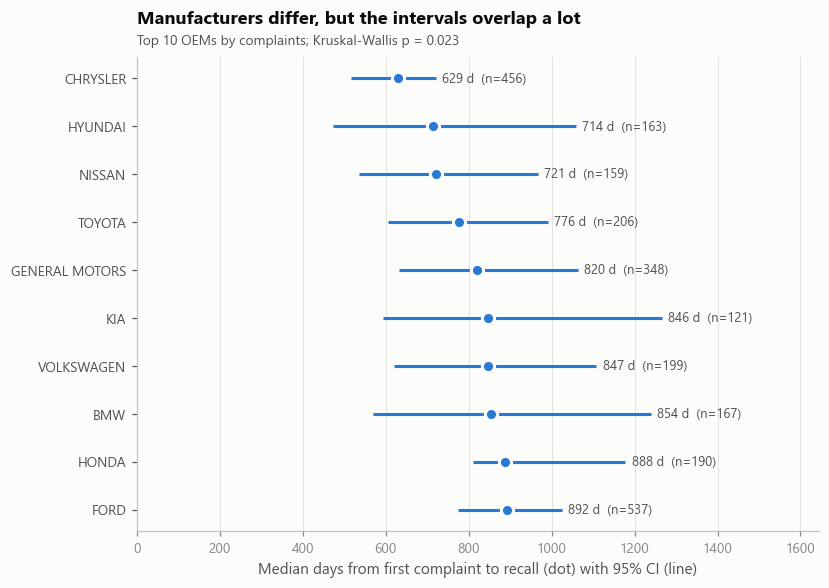

,oem,campaigns,median_lag_days,ci_low,ci_high,median_prior_complaints
1,CHRYSLER,456,629.0,515.0000,720.500,12.0
5,HYUNDAI,163,714.0,472.0000,1058.000,14.0
7,NISSAN,159,721.0,535.0000,966.225,7.0
8,TOYOTA,206,776.5,606.0000,991.500,8.5
3,GENERAL MOTORS,348,819.5,631.5000,1063.000,11.0
6,KIA,121,846.0,593.0000,1265.000,11.0
9,VOLKSWAGEN,199,847.0,621.0000,1108.000,10.0
0,BMW,167,854.0,568.0000,1239.000,8.0
4,HONDA,190,888.0,809.4875,1178.000,13.0
2,FORD,537,892.0,773.0000,1025.000,13.0


In [6]:
scope_oems = q("SELECT MFR_NAME_CLEAN FROM v2.scope_oems").MFR_NAME_CLEAN.tolist()
sub = camp[camp.MFR_NAME_CLEAN.isin(scope_oems)]
rows = []
for oem, g in sub.groupby("MFR_NAME_CLEAN"):
    med, lo, hi = median_ci(g.LAG_FIRST_DAYS)
    rows.append({"oem": oem, "campaigns": len(g), "median_lag_days": med, "ci_low": lo, "ci_high": hi,
                 "median_prior_complaints": g.PRIOR_COMPLAINTS.median()})
by_oem = save(pd.DataFrame(rows).sort_values("median_lag_days"), "03_lag_by_oem")

kw = stats.kruskal(*[g.LAG_FIRST_DAYS.values for _, g in sub.groupby("MFR_NAME_CLEAN")])
KEY["oem_kruskal_p"] = float(kw.pvalue)
KEY["oem_fastest"] = by_oem.iloc[0][["oem", "median_lag_days"]].to_dict()
KEY["oem_slowest"] = by_oem.iloc[-1][["oem", "median_lag_days"]].to_dict()
KEY["oem_spread_days"] = float(by_oem.median_lag_days.max() - by_oem.median_lag_days.min())
print(f"Kruskal-Wallis across OEMs: H={kw.statistic:.1f}, p={kw.pvalue:.2g}")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(by_oem) + 1.4))
y = np.arange(len(by_oem))
ax.hlines(y, by_oem.ci_low, by_oem.ci_high, color=BLUE, linewidth=2)
ax.plot(by_oem.median_lag_days, y, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
for yi, (_, r) in zip(y, by_oem.iterrows()):
    ax.text(r.ci_high + 15, yi, f"{r.median_lag_days:,.0f} d  (n={r.campaigns:,})", va="center", color=INK2, fontsize=8.5)
ax.set_yticks(y, by_oem.oem)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Median days from first complaint to recall (dot) with 95% CI (line)")
ax.set_xlim(0, by_oem.ci_high.max() * 1.3)
ax.set_title("Manufacturers differ, but the intervals overlap a lot", pad=22)
finish(fig, ax, "03_lag_by_oem", f"Top 10 OEMs by complaints; Kruskal-Wallis p = {kw.pvalue:.2g}")
by_oem

## 4. Lag by component

Kruskal-Wallis across components: p=1.6e-26
Variance in log-lag explained: OEM 0.9%, component 5.1%


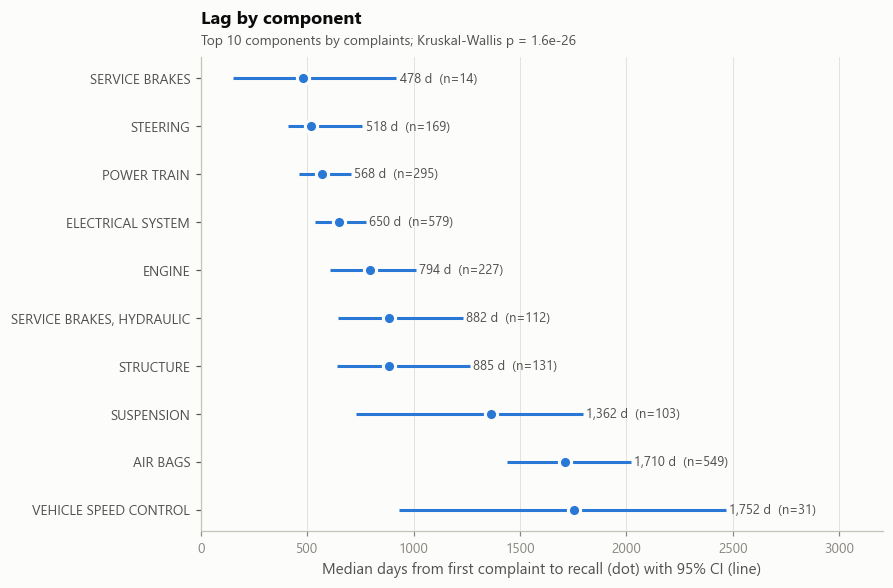

,component,campaigns,median_lag_days,ci_low,ci_high,median_prior_complaints
4,SERVICE BRAKES,14,478.0,153.0,918.5,12.0
6,STEERING,169,518.0,407.0,759.0,8.0
3,POWER TRAIN,295,568.0,460.0,703.0,12.0
1,ELECTRICAL SYSTEM,579,650.0,538.0,775.0,13.0
2,ENGINE,227,794.0,607.0,1012.0,16.0
5,"SERVICE BRAKES, HYDRAULIC",112,882.5,646.0,1232.5,5.0
7,STRUCTURE,131,885.0,638.0,1263.0,9.0
8,SUSPENSION,103,1362.0,729.0,1797.0,12.0
0,AIR BAGS,549,1710.0,1437.0,2020.0,28.0
9,VEHICLE SPEED CONTROL,31,1752.0,929.0,2466.0,26.0


In [7]:
scope_comp = q("SELECT COMPONENT_CLEAN FROM v2.scope_components").COMPONENT_CLEAN.tolist()
sub = camp[camp.PRIMARY_COMPONENT.isin(scope_comp)]
rows = []
for comp, g in sub.groupby("PRIMARY_COMPONENT"):
    med, lo, hi = median_ci(g.LAG_FIRST_DAYS)
    rows.append({"component": comp, "campaigns": len(g), "median_lag_days": med, "ci_low": lo, "ci_high": hi,
                 "median_prior_complaints": g.PRIOR_COMPLAINTS.median()})
by_comp = save(pd.DataFrame(rows).sort_values("median_lag_days"), "04_lag_by_component")
kw_c = stats.kruskal(*[g.LAG_FIRST_DAYS.values for _, g in sub.groupby("PRIMARY_COMPONENT")])
KEY["component_kruskal_p"] = float(kw_c.pvalue)
KEY["component_fastest"] = by_comp.iloc[0][["component", "median_lag_days"]].to_dict()
KEY["component_slowest"] = by_comp.iloc[-1][["component", "median_lag_days"]].to_dict()
KEY["component_spread_days"] = float(by_comp.median_lag_days.max() - by_comp.median_lag_days.min())

# Effect size comparison that is fair to both: how much of the variance in log-lag does each factor explain?
both = camp[camp.MFR_NAME_CLEAN.isin(scope_oems) & camp.PRIMARY_COMPONENT.isin(scope_comp)].copy()
both["log_lag"] = np.log1p(both.LAG_FIRST_DAYS)
def eta_sq(df, col):
    grand = df.log_lag.mean()
    ss_between = df.groupby(col).log_lag.apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return ss_between / ((df.log_lag - grand) ** 2).sum()
KEY["eta_sq_oem"] = round(float(eta_sq(both, "MFR_NAME_CLEAN")), 4)
KEY["eta_sq_component"] = round(float(eta_sq(both, "PRIMARY_COMPONENT")), 4)
print(f"Kruskal-Wallis across components: p={kw_c.pvalue:.2g}")
print(f"Variance in log-lag explained: OEM {KEY['eta_sq_oem']:.1%}, component {KEY['eta_sq_component']:.1%}")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(by_comp) + 1.4))
y = np.arange(len(by_comp))
ax.hlines(y, by_comp.ci_low, by_comp.ci_high, color=BLUE, linewidth=2)
ax.plot(by_comp.median_lag_days, y, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
for yi, (_, r) in zip(y, by_comp.iterrows()):
    ax.text(r.ci_high + 15, yi, f"{r.median_lag_days:,.0f} d  (n={r.campaigns:,})", va="center", color=INK2, fontsize=8.5)
ax.set_yticks(y, by_comp.component)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Median days from first complaint to recall (dot) with 95% CI (line)")
ax.set_xlim(0, by_comp.ci_high.max() * 1.3)
ax.set_title("Lag by component", pad=22)
finish(fig, ax, "04_lag_by_component", f"Top 10 components by complaints; Kruskal-Wallis p = {kw_c.pvalue:.2g}")
by_comp

## 5. Manufacturer × component

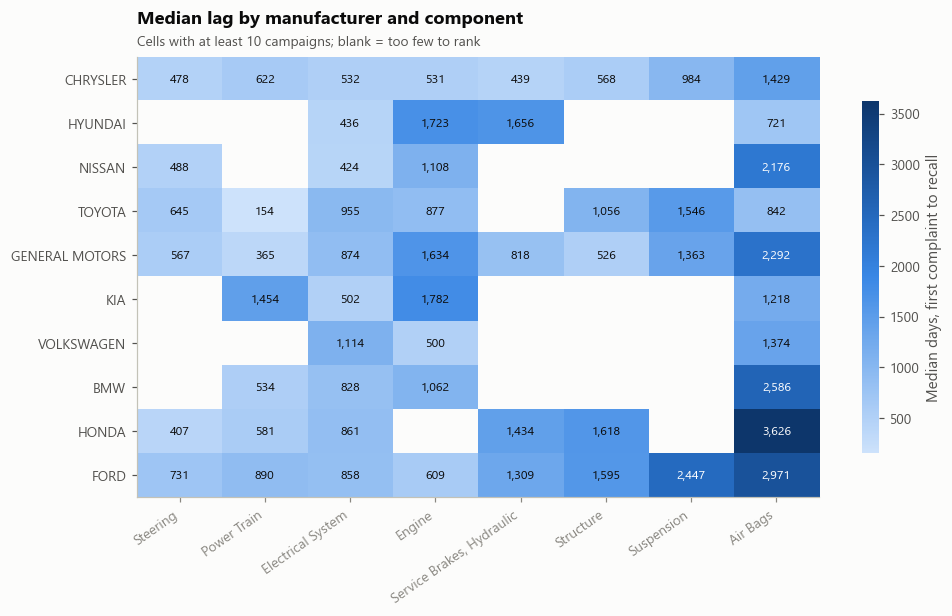

In [8]:
cell = (both.groupby(["MFR_NAME_CLEAN", "PRIMARY_COMPONENT"])
            .agg(campaigns=("CAMPNO", "size"), median_lag_days=("LAG_FIRST_DAYS", "median")).reset_index())
save(cell, "05_oem_component_crosstab")
grid = cell[cell.campaigns >= 10].pivot(index="MFR_NAME_CLEAN", columns="PRIMARY_COMPONENT", values="median_lag_days")
grid = grid.loc[[o for o in by_oem.oem if o in grid.index], [c for c in by_comp.component if c in grid.columns]]

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", SEQ)
fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(grid.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(grid.shape[1]), [c.title() for c in grid.columns], rotation=35, ha="right")
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
vmax = np.nanmax(grid.values)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=8,
                    color="#ffffff" if v > 0.55 * vmax else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Median days, first complaint to recall", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Median lag by manufacturer and component", pad=22)
finish(fig, ax, "05_oem_component_heatmap", "Cells with at least 10 campaigns; blank = too few to rank")

## 6. Severity by component

Deaths, injuries, crashes and fires per component. Each complaint is counted once per component, so a
complaint that lists several lines under the same component is not counted several times. Rates are shown
per 1,000 complaints, for components with at least 1,000 complaints.

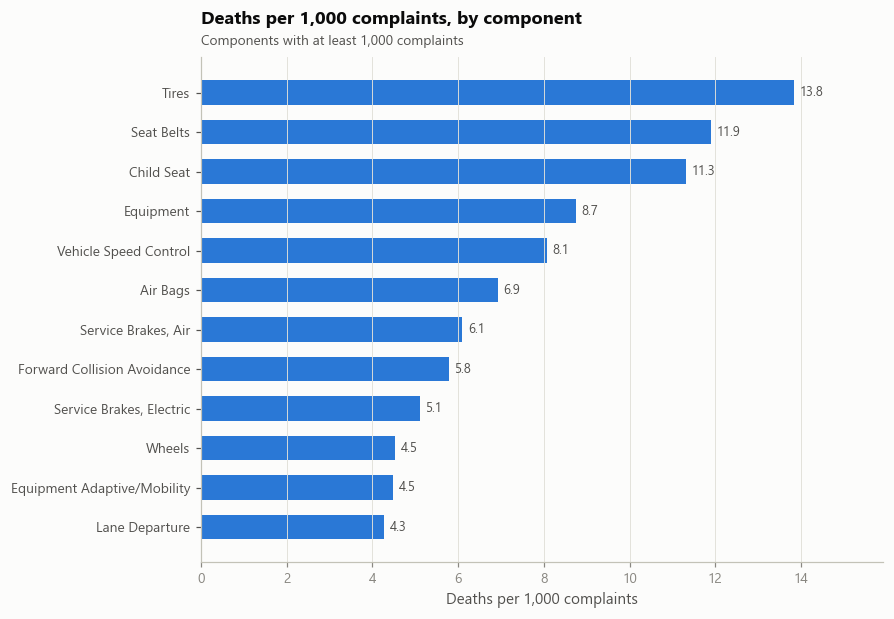

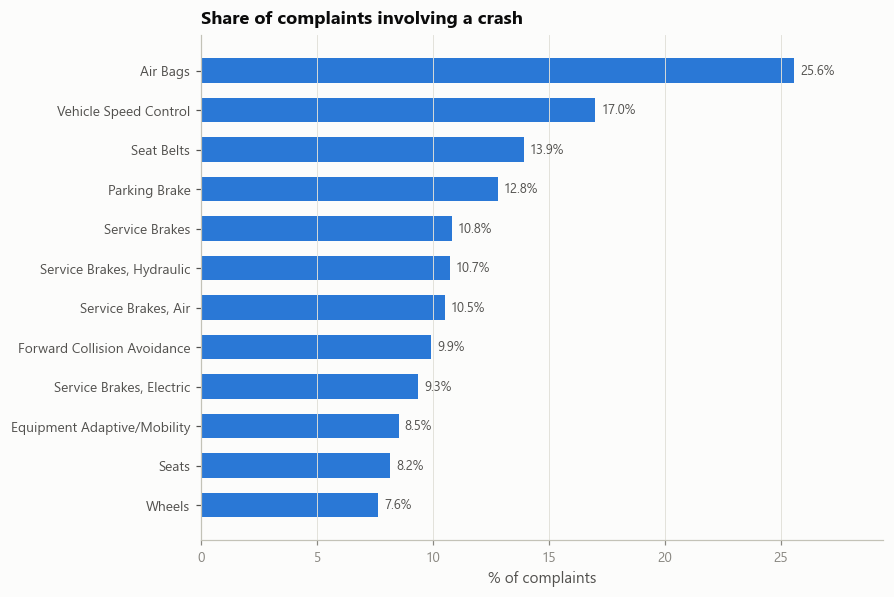

,COMPONENT_CLEAN,complaints,crash_complaints,fire_complaints,injury_complaints,fatal_complaints,people_injured,deaths,pct_crash,pct_fire,injured_per_1000,deaths_per_1000
0,TIRES,35396,2183,162,1531,210,2802,490,6.17,0.46,79.16,13.84
1,SEAT BELTS,37501,5217,205,5143,289,7286,446,13.91,0.55,194.29,11.89
2,CHILD SEAT,1149,72,4,87,12,146,13,6.27,0.35,127.07,11.31
3,EQUIPMENT,16816,535,478,521,34,722,147,3.18,2.84,42.94,8.74
4,VEHICLE SPEED CONTROL,82693,14052,2118,5401,292,7661,667,16.99,2.56,92.64,8.07
5,AIR BAGS,152799,39054,1050,28451,772,39046,1057,25.56,0.69,255.54,6.92
6,"SERVICE BRAKES, AIR",3768,396,40,144,11,203,23,10.51,1.06,53.87,6.10
7,FORWARD COLLISION AVOIDANCE,21440,2130,78,931,20,1435,124,9.93,0.36,66.93,5.78
8,"SERVICE BRAKES, ELECTRIC",2546,238,36,64,4,87,13,9.35,1.41,34.17,5.11
9,WHEELS,22293,1704,179,762,42,1087,101,7.64,0.80,48.76,4.53


In [9]:
sev = q("SELECT * FROM v2.vw_severity_by_component WHERE complaints >= 1000 ORDER BY deaths_per_1000 DESC")
tot = q("SELECT * FROM v2.vw_severity_totals")
save(sev, "06_severity_by_component")
KEY.update({
    "total_complaints": int(tot.complaints[0]), "total_deaths": int(tot.deaths[0]), "total_injured": int(tot.people_injured[0]),
    "severity_top_deaths_per_1000": sev.head(5)[["COMPONENT_CLEAN", "deaths_per_1000", "deaths", "complaints"]].to_dict("records"),
    "severity_top_total_deaths": sev.sort_values("deaths", ascending=False).head(5)[["COMPONENT_CLEAN", "deaths"]].to_dict("records"),
    "severity_top_crash_pct": sev.sort_values("pct_crash", ascending=False).head(3)[["COMPONENT_CLEAN", "pct_crash"]].to_dict("records"),
    "severity_top_fire_pct": sev.sort_values("pct_fire", ascending=False).head(3)[["COMPONENT_CLEAN", "pct_fire"]].to_dict("records"),
})
top = sev.head(12)
hbar(top.COMPONENT_CLEAN.str.title(), top.deaths_per_1000.astype(float),
     "Deaths per 1,000 complaints, by component", "Deaths per 1,000 complaints", "06_deaths_per_1000",
     subtitle="Components with at least 1,000 complaints", fmt="{:.1f}")
crash = sev.sort_values("pct_crash", ascending=False).head(12)
hbar(crash.COMPONENT_CLEAN.str.title(), crash.pct_crash.astype(float),
     "Share of complaints involving a crash", "% of complaints", "06_crash_rate", fmt="{:.1f}%")
sev.head(12)

## 7. Are severe complaints followed by a recall more often?

Per complaint, filed 2000 to 2 years before the extract (so every complaint had 2 full years to be
followed by a recall). Chi-square tests the recall rate across tiers; Mann-Whitney compares days to
recall for crash vs no-crash complaints that were recalled.

chi-square p = 2.3e-29; Mann-Whitney p = 4.9e-49, effect = -0.076


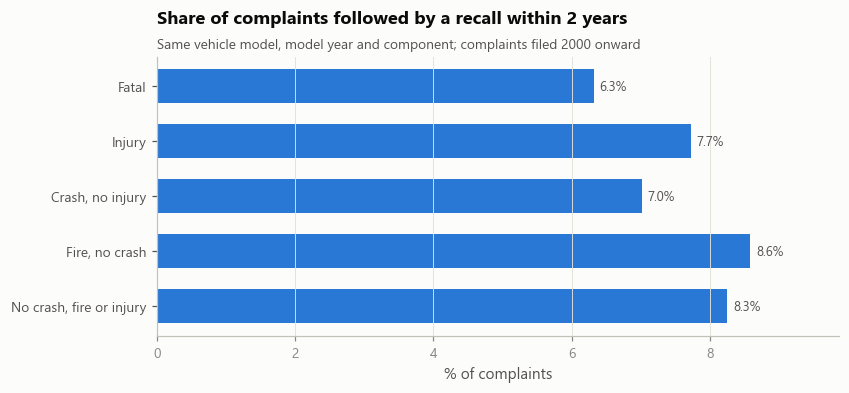

,SEVERITY_TIER,complaints,recalled_2y,pct_recalled_2y
0,1 Fatal,2707,171,6.316956
1,2 Injury,61653,4762,7.723874
2,"3 Crash, no injury",52398,3676,7.015535
3,"4 Fire, no crash",34261,2940,8.581186
4,"5 No crash, fire or injury",1429613,117947,8.250275


In [10]:
tiers = q("""
SELECT SEVERITY_TIER, COUNT(*) AS complaints, SUM(RECALLED_WITHIN_2Y) AS recalled_2y
FROM v2.vw_complaint_severity_outcome GROUP BY SEVERITY_TIER ORDER BY SEVERITY_TIER
""")
tiers["pct_recalled_2y"] = 100 * tiers.recalled_2y / tiers.complaints
chi = stats.chi2_contingency(np.c_[tiers.recalled_2y, tiers.complaints - tiers.recalled_2y])
save(tiers, "07_severity_vs_recall")
days = q("SELECT CRASH, DAYS_TO_NEXT_RECALL FROM v2.vw_complaint_severity_outcome WHERE NEXT_RECALL_DATE IS NOT NULL")
crash_d, nocrash_d = days[days.CRASH == 1].DAYS_TO_NEXT_RECALL, days[days.CRASH == 0].DAYS_TO_NEXT_RECALL
mw = stats.mannwhitneyu(crash_d, nocrash_d)
KEY.update({
    "severity_tiers": tiers.round(2).to_dict("records"), "severity_chi2_p": float(chi.pvalue),
    "median_days_crash": float(crash_d.median()), "median_days_no_crash": float(nocrash_d.median()),
    "n_crash_recalled": int(len(crash_d)), "n_no_crash_recalled": int(len(nocrash_d)),
    "mw_crash_p": float(mw.pvalue),
    # rank-biserial effect size: 0 = no difference, +-1 = complete separation
    "mw_crash_effect": float(1 - 2 * mw.statistic / (len(crash_d) * len(nocrash_d))),
})
print(f"chi-square p = {chi.pvalue:.2g}; Mann-Whitney p = {mw.pvalue:.2g}, effect = {KEY['mw_crash_effect']:.3f}")
hbar(tiers.SEVERITY_TIER.str[2:], tiers.pct_recalled_2y,
     "Share of complaints followed by a recall within 2 years", "% of complaints", "07_severity_vs_recall",
     subtitle="Same vehicle model, model year and component; complaints filed 2000 onward", fmt="{:.1f}%")
tiers

## 8. Trends over time (separate charts, no dual axis)

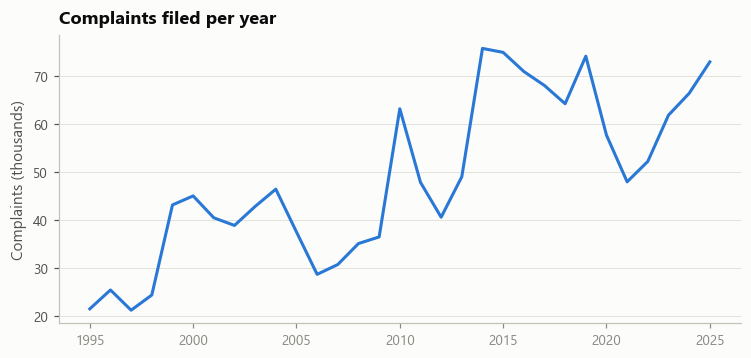

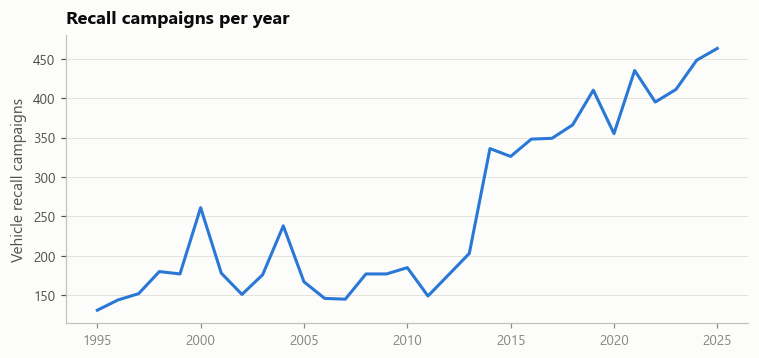

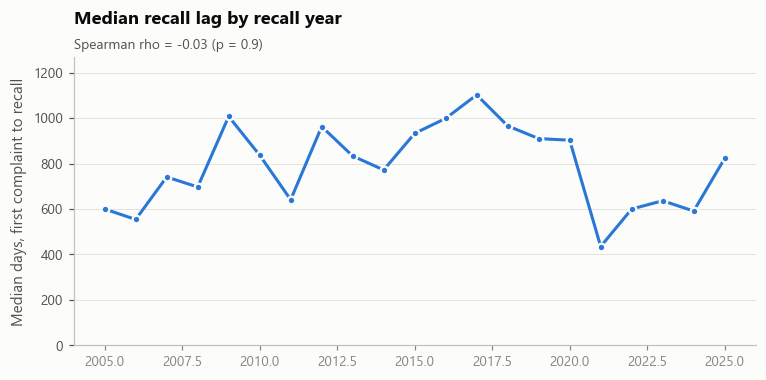

,RECALL_YEAR,campaigns,median_lag_first,median_lag_signal,median_prior_complaints
0,2005,67,600.0,556.0,10.0
1,2006,67,554.0,645.0,5.0
2,2007,65,741.0,913.0,9.0
3,2008,73,697.0,869.0,6.0
4,2009,68,1007.5,1341.0,7.0
5,2010,91,837.0,888.0,11.0
6,2011,73,641.0,979.0,11.0
7,2012,79,963.0,1434.5,19.0
8,2013,108,833.5,923.0,10.0
9,2014,176,772.0,1194.0,10.5


In [11]:
vol = q("SELECT * FROM v2.vw_yearly_volume ORDER BY year")
ext_year = pd.Timestamp(q("SELECT EXTRACT_DATE FROM v2.params").iloc[0, 0]).year
vol = vol[(vol.year >= 1995) & (vol.year < ext_year)]   # drop the partial final year
save(vol, "08_yearly_volume")
trend = q("SELECT * FROM v2.vw_lag_by_recall_year ORDER BY RECALL_YEAR")
trend = trend[trend.RECALL_YEAR < ext_year]
save(trend, "08_lag_by_recall_year")
rho = stats.spearmanr(trend.RECALL_YEAR, trend.median_lag_first)
KEY["trend_spearman_rho"] = float(rho.statistic); KEY["trend_spearman_p"] = float(rho.pvalue)
KEY["trend_first_last"] = trend.iloc[[0, -1]][["RECALL_YEAR", "median_lag_first", "campaigns"]].to_dict("records")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(vol.year, vol.complaints / 1000, color=BLUE, linewidth=2)
ax.set_ylabel("Complaints (thousands)")
ax.set_title("Complaints filed per year", pad=8)
ax.grid(axis="x", visible=False)
finish(fig, ax, "08a_complaints_per_year")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(vol.year, vol.recall_campaigns, color=BLUE, linewidth=2)
ax.set_ylabel("Vehicle recall campaigns")
ax.set_title("Recall campaigns per year", pad=8)
ax.grid(axis="x", visible=False)
finish(fig, ax, "08b_recalls_per_year")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(trend.RECALL_YEAR, trend.median_lag_first, color=BLUE, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.set_ylabel("Median days, first complaint to recall")
ax.set_ylim(0, trend.median_lag_first.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_title("Median recall lag by recall year", pad=22)
finish(fig, ax, "08c_lag_by_recall_year", f"Spearman rho = {rho.statistic:.2f} (p = {rho.pvalue:.2g})")
trend

## 9. How often does a complaint lead to a recall?

Complaints filed 2000 to 5 years before the extract; recall must cover the same model, model year
and component.

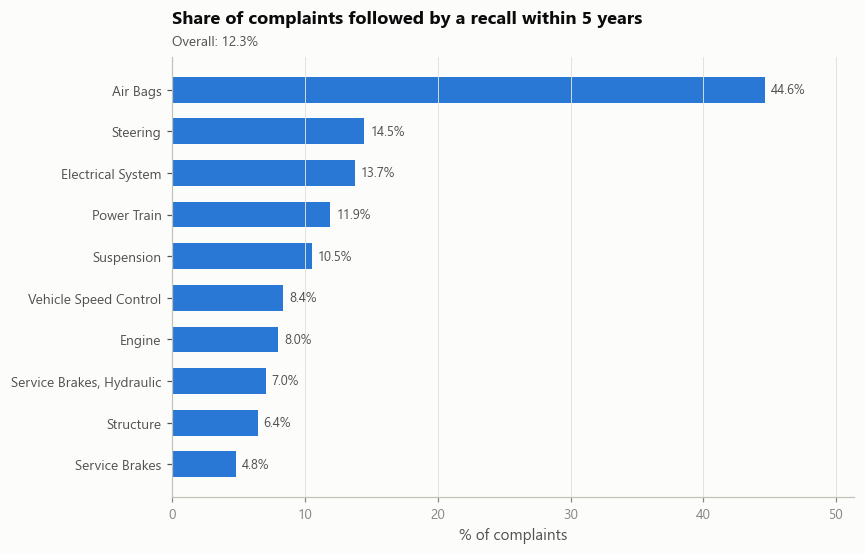

,COMPONENT_CLEAN,complaints,pct_recalled_1y,pct_recalled_2y,pct_recalled_5y
0,AIR BAGS,126900,19.99,29.23,44.65
1,STEERING,103068,6.26,8.90,14.46
2,ELECTRICAL SYSTEM,164818,5.62,8.42,13.73
3,POWER TRAIN,144408,4.90,7.86,11.91
4,SUSPENSION,63613,5.31,7.80,10.53
5,VEHICLE SPEED CONTROL,63310,3.43,5.70,8.38
6,ENGINE,178337,3.27,5.26,8.00
7,"SERVICE BRAKES, HYDRAULIC",58323,2.87,4.07,7.05
8,STRUCTURE,72937,3.27,4.81,6.44
9,SERVICE BRAKES,49907,2.33,2.98,4.80


In [12]:
overall = q("""
SELECT COUNT(*) AS complaints, AVG(1.0*RECALLED_1Y) AS r1, AVG(1.0*RECALLED_2Y) AS r2, AVG(1.0*RECALLED_5Y) AS r5
FROM v2.vw_complaint_recall_rate""")
rate_comp = q("""SELECT c.* FROM v2.vw_recall_rate_by_component c
                 JOIN v2.scope_components s ON s.COMPONENT_CLEAN = c.COMPONENT_CLEAN ORDER BY pct_recalled_5y DESC""")
rate_oem = q("""SELECT o.* FROM v2.vw_recall_rate_by_oem o
                JOIN v2.scope_oems s ON s.MFR_NAME_CLEAN = o.MFR_NAME_CLEAN ORDER BY pct_recalled_5y DESC""")
save(rate_comp, "09_recall_rate_by_component"); save(rate_oem, "09_recall_rate_by_oem")
KEY.update({"recall_rate_complaints": int(overall.complaints[0]),
            "recall_rate_1y": round(100 * overall.r1[0], 2), "recall_rate_2y": round(100 * overall.r2[0], 2),
            "recall_rate_5y": round(100 * overall.r5[0], 2),
            "recall_rate_by_component": rate_comp[["COMPONENT_CLEAN", "pct_recalled_5y"]].to_dict("records"),
            "recall_rate_by_oem": rate_oem[["MFR_NAME_CLEAN", "pct_recalled_5y"]].to_dict("records")})
hbar(rate_comp.COMPONENT_CLEAN.str.title(), rate_comp.pct_recalled_5y.astype(float),
     "Share of complaints followed by a recall within 5 years", "% of complaints", "09_recall_rate_by_component",
     subtitle=f"Overall: {KEY['recall_rate_5y']:.1f}%", fmt="{:.1f}%")
rate_comp

## 10. Do complaint spikes predict recalls?

Organic spikes: 24.27% followed by recall in 6 months vs 26.99% for normal months (lift 0.9x, Fisher p = 0.048)


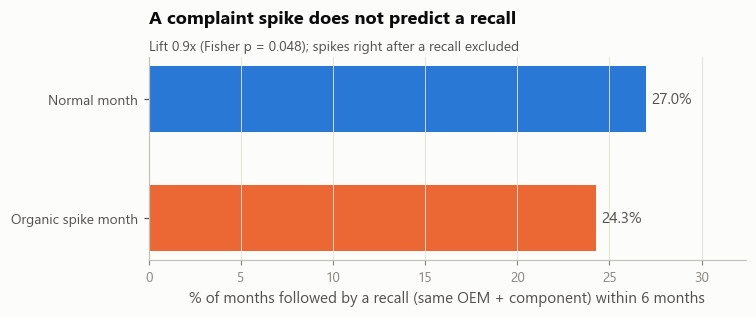

,spike_context,month_type,months,months_followed_by_recall,pct_recall_next_6m
0,After a recent recall,Normal month,8493,4747,55.89
1,After a recent recall,Spike month,344,201,58.43
2,Organic (no recent recall),Normal month,33710,9098,26.99
3,Organic (no recent recall),Spike month,1096,266,24.27


In [13]:
lift = save(q("SELECT * FROM v2.vw_spike_lift ORDER BY spike_context, month_type"), "10_spike_lift")
after = save(q("SELECT * FROM v2.vw_spike_after_recall"), "10_spike_after_recall")
before = save(q("SELECT * FROM v2.vw_spike_before_recall"), "10_spike_before_recall")
org = lift[lift.spike_context.str.startswith("Organic")].set_index("month_type")
p_spike, p_norm = org.loc["Spike month", "pct_recall_next_6m"], org.loc["Normal month", "pct_recall_next_6m"]
ct = np.array([[org.loc["Spike month", "months_followed_by_recall"], org.loc["Spike month", "months"] - org.loc["Spike month", "months_followed_by_recall"]],
               [org.loc["Normal month", "months_followed_by_recall"], org.loc["Normal month", "months"] - org.loc["Normal month", "months_followed_by_recall"]]])
fisher = stats.fisher_exact(ct)
aft = after.set_index("context")
KEY.update({"spike_lift": lift.to_dict("records"), "spike_after_recall": after.to_dict("records"),
            "spike_before_recall": before.to_dict("records"),
            "organic_spike_recall_pct": float(p_spike), "normal_month_recall_pct": float(p_norm),
            "spike_lift_ratio": round(float(p_spike) / float(p_norm), 2), "spike_fisher_p": float(fisher.pvalue),
            "organic_spike_months": int(org.loc["Spike month", "months"])})
print(f"Organic spikes: {p_spike}% followed by recall in 6 months vs {p_norm}% for normal months "
      f"(lift {KEY['spike_lift_ratio']}x, Fisher p = {fisher.pvalue:.2g})")

labels = ["Normal month", "Organic spike month"]
vals = [float(p_norm), float(p_spike)]
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh([0, 1], vals, color=[BLUE, ORANGE], height=0.55)
ax.set_yticks([0, 1], labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for i, v in enumerate(vals):
    ax.text(v + max(vals) * 0.01, i, f"{v:.1f}%", va="center", color=INK2)
ax.set_xlim(0, max(vals) * 1.2)
ax.set_xlabel("% of months followed by a recall (same OEM + component) within 6 months")
verdict = ("A complaint spike raises the odds of a recall" if KEY["spike_lift_ratio"] >= 1.2 and fisher.pvalue < 0.05
           else "A complaint spike does not predict a recall")
ax.set_title(verdict, pad=22)
finish(fig, ax, "10_spike_lift", f"Lift {KEY['spike_lift_ratio']}x (Fisher p = {fisher.pvalue:.2g}); spikes right after a recall excluded")
lift

## 11. Air bag recalls by failure mode

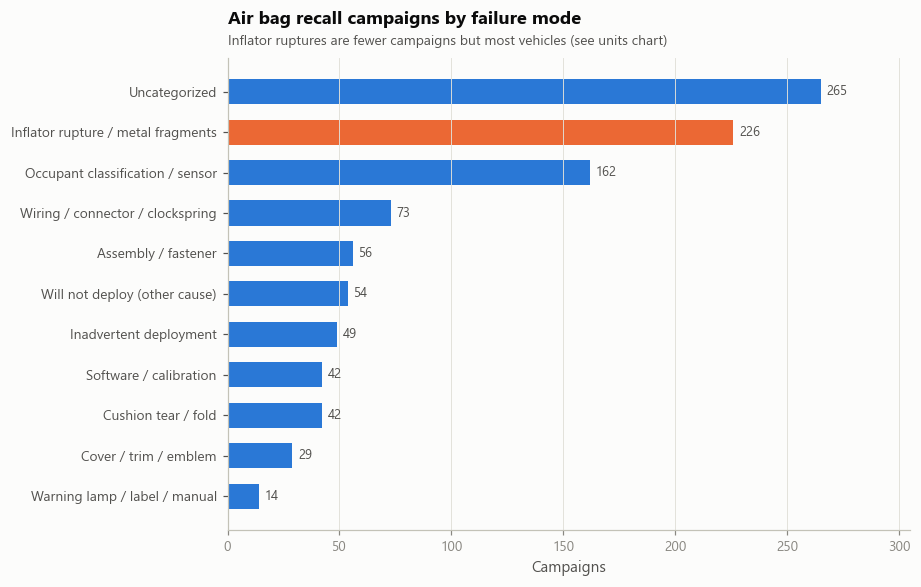

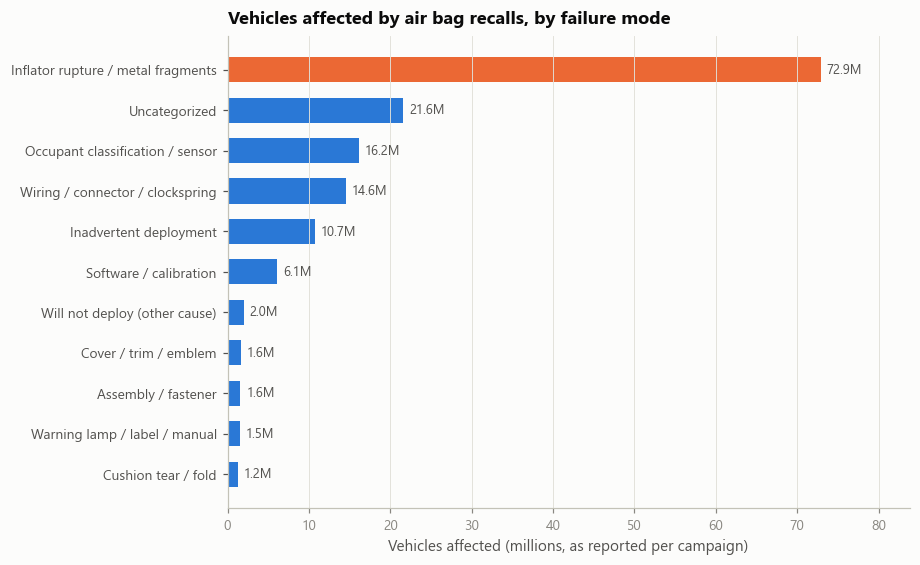

,CATEGORY,campaigns,pct_campaigns,units_affected,pct_units
0,Uncategorized,265,26.2,21561504,14.4
1,Inflator rupture / metal fragments,226,22.3,72875856,48.6
2,Occupant classification / sensor,162,16.0,16152072,10.8
3,Wiring / connector / clockspring,73,7.2,14568109,9.7
4,Assembly / fastener,56,5.5,1555733,1.0
5,Will not deploy (other cause),54,5.3,1988348,1.3
6,Inadvertent deployment,49,4.8,10733383,7.2
7,Software / calibration,42,4.2,6056011,4.0
8,Cushion tear / fold,42,4.2,1220909,0.8
9,Cover / trim / emblem,29,2.9,1646781,1.1


In [14]:
ab = save(q("SELECT * FROM v2.vw_airbag_categories ORDER BY campaigns DESC"), "11_airbag_categories")
KEY["airbag_categories"] = ab.to_dict("records")
KEY["airbag_campaigns"] = int(ab.campaigns.sum())
hbar(ab.CATEGORY, ab.campaigns, "Air bag recall campaigns by failure mode", "Campaigns", "11_airbag_campaigns",
     highlight={"Inflator rupture / metal fragments"},
     subtitle="Inflator ruptures are fewer campaigns but most vehicles (see units chart)")
abu = ab.sort_values("units_affected", ascending=False)
hbar(abu.CATEGORY, abu.units_affected / 1e6, "Vehicles affected by air bag recalls, by failure mode",
     "Vehicles affected (millions, as reported per campaign)", "11_airbag_units", fmt="{:.1f}M",
     highlight={"Inflator rupture / metal fragments"})
ab

## 12. Manufacturer-initiated vs NHTSA-influenced recalls

Lag: p = 2.1e-76; prior complaints: p = 6.2e-87


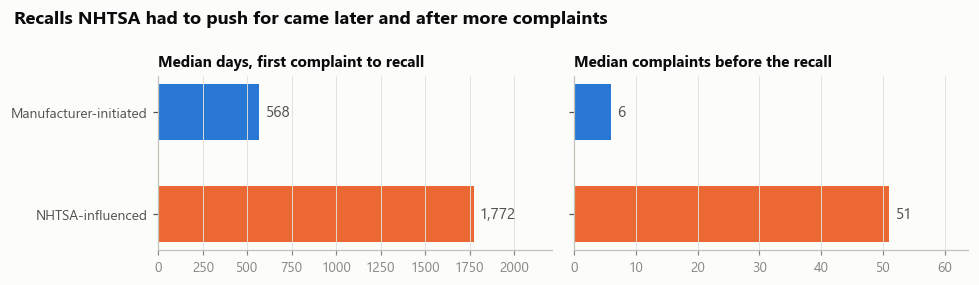

,RECALL_ORIGIN,campaigns,median_lag_first,median_prior_complaints,median_units_affected
0,Manufacturer-initiated,2504,568.0,6.0,19126.0
1,NHTSA-influenced,742,1772.5,51.0,94597.0


In [15]:
origin = save(q("SELECT * FROM v2.vw_origin_summary"), "12_origin_summary")
lag_origin = save(q("SELECT * FROM v2.vw_lag_by_origin"), "12_lag_by_origin")
by_oem_origin = save(q("""SELECT o.* FROM v2.vw_origin_by_oem o JOIN v2.scope_oems s ON s.MFR_NAME_CLEAN = o.MFR_NAME_CLEAN
                          ORDER BY pct_nhtsa_influenced DESC"""), "12_origin_by_oem")
a = camp[camp.RECALL_ORIGIN == "NHTSA-influenced"]
b = camp[camp.RECALL_ORIGIN == "Manufacturer-initiated"]
mw_lag = stats.mannwhitneyu(a.LAG_FIRST_DAYS, b.LAG_FIRST_DAYS)
mw_cnt = stats.mannwhitneyu(a.PRIOR_COMPLAINTS, b.PRIOR_COMPLAINTS)
KEY.update({"origin_summary": origin.to_dict("records"), "lag_by_origin": lag_origin.to_dict("records"),
            "origin_lag_p": float(mw_lag.pvalue), "origin_complaints_p": float(mw_cnt.pvalue),
            "origin_by_oem": by_oem_origin.to_dict("records")})
print(f"Lag: p = {mw_lag.pvalue:.2g}; prior complaints: p = {mw_cnt.pvalue:.2g}")

lo = lag_origin.set_index("RECALL_ORIGIN").loc[["Manufacturer-initiated", "NHTSA-influenced"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
for ax, col, title, fmt in [(axes[0], "median_lag_first", "Median days, first complaint to recall", "{:,.0f}"),
                            (axes[1], "median_prior_complaints", "Median complaints before the recall", "{:,.0f}")]:
    ax.barh([0, 1], lo[col], color=[BLUE, ORANGE], height=0.55)
    ax.set_yticks([0, 1], lo.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    for i, v in enumerate(lo[col]):
        ax.text(v + lo[col].max() * 0.02, i, fmt.format(v), va="center", color=INK2)
    ax.set_xlim(0, lo[col].max() * 1.25)
    ax.set_title(title, fontsize=10)
axes[1].set_yticks([0, 1], ["", ""])
fig.suptitle("Recalls NHTSA had to push for came later and after more complaints", x=0.02, ha="left",
             fontweight="bold", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(CHARTS / "12_origin.png"); plt.show(); plt.close(fig)
lag_origin

## Save key numbers

In [16]:
def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, list): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 6)
    if hasattr(o, "item"): return o.item()
    return o
(RES / "key_numbers.json").write_text(json.dumps(clean(KEY), indent=2, default=str))
print("Saved", RES / "key_numbers.json", "with", len(KEY), "entries")

Saved D:\DA project\NHTSA PROJECT\Results\key_numbers.json with 67 entries
